# Phase 2 — Notebook 1: 3-Qubit Bit-Flip Error Correction Code

## What this notebook does:
We build a circuit that **protects a qubit against bit-flip errors** using 3 qubits.
Then we test it: inject noise at different levels and measure whether the code actually helps.

## The 4 stages of the circuit:
1. **Encoding** — spread 1 qubit's info across 3 qubits using CNOTs
2. **Noise** — simulate errors hitting the qubits
3. **Syndrome + Correction** — detect which qubit (if any) flipped, and fix it
4. **Decoding + Measurement** — collapse back to 1 qubit and check the result

## What we measure:
- **Logical error rate** = how often does the CORRECTED qubit still have an error?
- **Fidelity** = how close is the corrected state to the original?
- **Comparison** with Phase 1 baseline (no correction)

---
## Step 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector, state_fidelity

from qiskit_aer import AerSimulator
from qiskit_aer.noise import (
    NoiseModel,
    pauli_error,
    depolarizing_error,
    amplitude_damping_error,
)

plt.rcParams['figure.dpi'] = 110
np.random.seed(42)

print('Libraries loaded!')

Libraries loaded!


---
## Step 2: Build the Bit-Flip Correction Circuit

This is the heart of the notebook. We build the full pipeline:

```
Prepare qubit → Encode (spread across 3) → Noise hits → Detect error → Fix it → Decode → Measure
```

### Qubit layout:
- **q0, q1, q2** = the 3 data qubits (q0 is the original, q1 and q2 are helpers)
- **a0, a1** = 2 ancilla (syndrome) qubits that detect which qubit has an error

### How the syndrome works:
| a0 | a1 | Meaning | Action |
|----|----|---------|--------|
| 0  | 0  | No error | Do nothing |
| 1  | 0  | q0 flipped | Flip q0 back |
| 1  | 1  | q1 flipped | Flip q1 back |
| 0  | 1  | q2 flipped | Flip q2 back |

Total qubits: 5 (3 data + 2 ancilla)
Total classical bits: 3 (2 syndrome + 1 output)



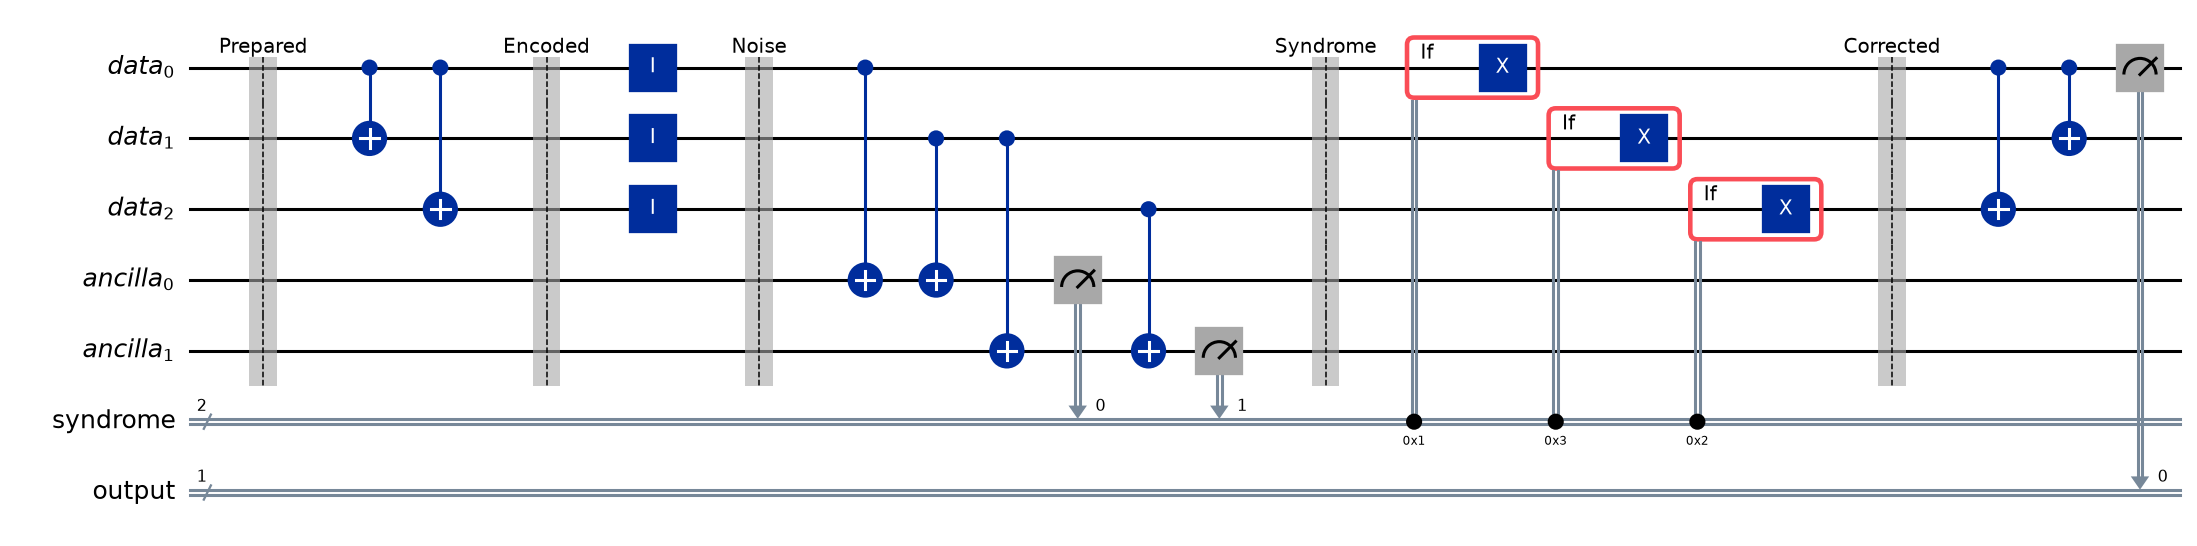

In [2]:
def build_bitflip_circuit(initial_state='0', add_noise_gate=True):
    """
    Build the full 3-qubit bit-flip error correction circuit.
    
    Args:
        initial_state: '0', '1', or '+' — the state we want to protect
        add_noise_gate: if True, adds idle gates where noise will attach
    
    Returns:
        The complete quantum circuit
    """
    
    # === CREATE REGISTERS ===
    data = QuantumRegister(3, 'data')       # 3 data qubits: data[0], data[1], data[2]
    ancilla = QuantumRegister(2, 'ancilla')  # 2 syndrome qubits: ancilla[0], ancilla[1]
    syndrome_bits = ClassicalRegister(2, 'syndrome')  # 2 classical bits to store syndrome result
    output_bit = ClassicalRegister(1, 'output')       # 1 classical bit for final measurement
    
    circuit = QuantumCircuit(data, ancilla, syndrome_bits, output_bit)
    
    # ==========================================
    # STAGE 1: PREPARE THE INITIAL STATE
    # ==========================================
    # Set data[0] to the state we want to protect
    if initial_state == '1':
        circuit.x(data[0])        # |0⟩ → |1⟩
    elif initial_state == '+':
        circuit.h(data[0])        # |0⟩ → |+⟩ (superposition)
    
    circuit.barrier(label='Prepared')  # Visual separator in circuit diagram
    
    # ==========================================
    # STAGE 2: ENCODING (spread across 3 qubits)
    # ==========================================
    # CNOT from data[0] → data[1]: if data[0]=1, flip data[1]
    # CNOT from data[0] → data[2]: if data[0]=1, flip data[2]
    # After this: |0⟩ → |000⟩,  |1⟩ → |111⟩,  |+⟩ → (|000⟩ + |111⟩)/√2
    circuit.cx(data[0], data[1])
    circuit.cx(data[0], data[2])
    
    circuit.barrier(label='Encoded')
    
    # ==========================================
    # STAGE 3: NOISE (idle gates where noise attaches)
    # ==========================================
    if add_noise_gate:
        # Apply idle gate to ALL 3 data qubits
        # The noise model will attach errors to these gates
        circuit.id(data[0])
        circuit.id(data[1])
        circuit.id(data[2])
    
    circuit.barrier(label='Noise')
    
    # ==========================================
    # STAGE 4: SYNDROME MEASUREMENT (detect the error)
    # ==========================================
    # ancilla[0] checks: are data[0] and data[1] the same?
    circuit.cx(data[0], ancilla[0])   # CNOT: data[0] → ancilla[0]
    circuit.cx(data[1], ancilla[0])   # CNOT: data[1] → ancilla[0]
    # If data[0] == data[1], ancilla[0] stays 0
    # If data[0] != data[1], ancilla[0] becomes 1
    
    # ancilla[1] checks: are data[1] and data[2] the same?
    circuit.cx(data[1], ancilla[1])   # CNOT: data[1] → ancilla[1]
    circuit.cx(data[2], ancilla[1])   # CNOT: data[2] → ancilla[1]
    # If data[1] == data[2], ancilla[1] stays 0
    # If data[1] != data[2], ancilla[1] becomes 1
    
    # Measure the ancillas to read the syndrome
    circuit.measure(ancilla[0], syndrome_bits[0])
    circuit.measure(ancilla[1], syndrome_bits[1])
    
    circuit.barrier(label='Syndrome')
    
    # ==========================================
    # STAGE 5: ERROR CORRECTION (fix the broken qubit)
    # ==========================================
    # Based on syndrome, apply X gate to the flipped qubit.
    # Qiskit 2.x removed InstructionSet.c_if() — classically-conditioned
    # gates are now expressed with the if_test control-flow context manager.
    
    # Syndrome = 01 (binary) = 1 → data[0] was flipped → fix data[0]
    with circuit.if_test((syndrome_bits, 1)):
        circuit.x(data[0])
    
    # Syndrome = 11 (binary) = 3 → data[1] was flipped → fix data[1]
    with circuit.if_test((syndrome_bits, 3)):
        circuit.x(data[1])
    
    # Syndrome = 10 (binary) = 2 → data[2] was flipped → fix data[2]
    with circuit.if_test((syndrome_bits, 2)):
        circuit.x(data[2])
    
    circuit.barrier(label='Corrected')
    
    # ==========================================
    # STAGE 6: DECODING (collapse back to 1 qubit)
    # ==========================================
    # Reverse the encoding CNOTs
    circuit.cx(data[0], data[2])
    circuit.cx(data[0], data[1])
    
    # Measure the original data qubit
    circuit.measure(data[0], output_bit[0])
    
    return circuit


# Build and display an example circuit
example_circuit = build_bitflip_circuit('0')
print(f'Total qubits: {example_circuit.num_qubits} (3 data + 2 ancilla)')
print(f'Total classical bits: {example_circuit.num_clbits} (2 syndrome + 1 output)')
print()
example_circuit.draw('mpl', fold=40)

---
## Step 3: Noise Models (same as Phase 1)

We reuse the same 3 noise types, but now noise is applied to all 3 data qubits (not just 1).

In [3]:
def make_bit_flip_noise(p):
    """Bit-Flip: with probability p, flip the qubit (X gate)."""
    error = pauli_error([('X', p), ('I', 1 - p)])
    noise_model = NoiseModel()
    noise_model.add_all_qubit_quantum_error(error, ['id'])
    return noise_model


def make_depolarizing_noise(p):
    """Depolarizing: with probability p, apply a random error (X, Y, or Z)."""
    error = depolarizing_error(p, 1)
    noise_model = NoiseModel()
    noise_model.add_all_qubit_quantum_error(error, ['id'])
    return noise_model


def make_amplitude_damping_noise(gamma):
    """Amplitude Damping: |1⟩ decays to |0⟩ with probability gamma."""
    error = amplitude_damping_error(gamma)
    noise_model = NoiseModel()
    noise_model.add_all_qubit_quantum_error(error, ['id'])
    return noise_model


noise_makers = {
    'Bit-Flip':          make_bit_flip_noise,
    'Depolarizing':      make_depolarizing_noise,
    'Amplitude Damping': make_amplitude_damping_noise,
}

print('Noise models ready!')

Noise models ready!


---
## Step 4: Sanity Check — Does Correction Actually Fix Errors?

Before the full experiment, one quick test:
- Prepare |0⟩, encode it, apply 10% bit-flip noise, correct, decode, measure 5000 times
- Compare with the UNCORRECTED case (just noise, no code)

If the code works, the corrected version should have fewer errors.

In [4]:
noise_prob = 0.10  # 10% chance of bit-flip per qubit
shots = 5000

# --- WITH correction (our 3-qubit code) ---
corrected_circuit = build_bitflip_circuit('0')
noisy_sim = AerSimulator(noise_model=make_bit_flip_noise(noise_prob))
corrected_counts = noisy_sim.run(corrected_circuit, shots=shots).result().get_counts()

# The output bit is the FIRST register in the bitstring
# (Qiskit lists the most-recently-added classical register leftmost,
# and output_bit was created after syndrome_bits)
# Count how many times output was '1' (meaning error survived correction)
corrected_errors = sum(count for bitstring, count in corrected_counts.items()
                       if bitstring.split()[0] == '1')
corrected_error_rate = corrected_errors / shots

# --- WITHOUT correction (single qubit, just noise) ---
bare_circuit = QuantumCircuit(1, 1)
bare_circuit.id(0)         # Idle gate where noise attaches
bare_circuit.measure(0, 0)

bare_sim = AerSimulator(noise_model=make_bit_flip_noise(noise_prob))
bare_counts = bare_sim.run(bare_circuit, shots=shots).result().get_counts()
bare_errors = bare_counts.get('1', 0)
bare_error_rate = bare_errors / shots

print(f'Physical error rate (no correction):  {bare_error_rate:.4f}  ({bare_errors}/{shots} flipped)')
print(f'Logical error rate (with correction):  {corrected_error_rate:.4f}  ({corrected_errors}/{shots} flipped)')
print()
if corrected_error_rate < bare_error_rate:
    improvement = (1 - corrected_error_rate / bare_error_rate) * 100
    print(f'The code HELPED! Error reduced by {improvement:.1f}%')
else:
    print('The code did NOT help at this noise level (noise too high?)')

Physical error rate (no correction):  0.1012  (506/5000 flipped)
Logical error rate (with correction):  0.0272  (136/5000 flipped)

The code HELPED! Error reduced by 73.1%


---
## Step 5: Full Experiment — Logical Error Rate vs Physical Error Rate

Now the real experiment. For each noise type and noise level (1% to 20%):

1. Run the corrected circuit → get **logical error rate** (errors that survived correction)
2. Run a bare qubit → get **physical error rate** (errors without any correction)
3. Compare them

We test with initial state |0⟩ and |1⟩ (the states bit-flip code is designed to protect).

In [5]:
# Noise levels to test (matching Phase 1)
noise_levels = [0.001, 0.005, 0.01, 0.02, 0.05, 0.08, 0.10, 0.12, 0.15, 0.18, 0.20]
shots = 10000  # More shots = more accurate results
test_states = ['0', '1']


def get_logical_error_rate(initial_state, noise_type, noise_prob, num_shots):
    """
    Run the bit-flip correction circuit and measure how often
    the output is WRONG (different from what we started with).
    """
    # Build the correction circuit
    circuit = build_bitflip_circuit(initial_state)
    
    # Create noisy simulator
    noise_model = noise_makers[noise_type](noise_prob)
    sim = AerSimulator(noise_model=noise_model)
    
    # Run and get counts
    counts = sim.run(circuit, shots=num_shots).result().get_counts()
    
    # Figure out which output value is "wrong"
    # If we started with |0⟩, getting '1' is wrong
    # If we started with |1⟩, getting '0' is wrong
    wrong_output = '1' if initial_state == '0' else '0'
    
    # Count errors: check the OUTPUT bit (first register in the bitstring —
    # output_bit was created after syndrome_bits, so Qiskit lists it leftmost)
    errors = 0
    for bitstring, count in counts.items():
        output = bitstring.split()[0]
        if output == wrong_output:
            errors += count
    
    return errors / num_shots


def get_physical_error_rate(initial_state, noise_type, noise_prob, num_shots):
    """
    Run a bare qubit (NO correction) and measure how often
    the output is wrong. This is our baseline.
    """
    circuit = QuantumCircuit(1, 1)
    if initial_state == '1':
        circuit.x(0)
    circuit.id(0)          # Noise attaches here
    circuit.measure(0, 0)
    
    noise_model = noise_makers[noise_type](noise_prob)
    sim = AerSimulator(noise_model=noise_model)
    counts = sim.run(circuit, shots=num_shots).result().get_counts()
    
    wrong_output = '1' if initial_state == '0' else '0'
    errors = counts.get(wrong_output, 0)
    
    return errors / num_shots


# === RUN ALL EXPERIMENTS ===
all_results = []

for noise_type in noise_makers:
    for state in test_states:
        for p in noise_levels:
            logical_err = get_logical_error_rate(state, noise_type, p, shots)
            physical_err = get_physical_error_rate(state, noise_type, p, shots)
            
            all_results.append({
                'noise_type': noise_type,
                'initial_state': f'|{state}⟩',
                'noise_prob': p,
                'physical_error_rate': round(physical_err, 5),
                'logical_error_rate': round(logical_err, 5),
                'code_helps': logical_err < physical_err,  # Did correction reduce errors?
            })
            
print(f'Done! Ran {len(all_results)} experiments.')

results_df = pd.DataFrame(all_results)
results_df.head(10)

Done! Ran 66 experiments.


,noise_type,initial_state,noise_prob,physical_error_rate,logical_error_rate,code_helps
0,Bit-Flip,|0⟩,0.001,0.0012,0.0000,True
1,Bit-Flip,|0⟩,0.005,0.0057,0.0000,True
2,Bit-Flip,|0⟩,0.010,0.0092,0.0003,True
3,Bit-Flip,|0⟩,0.020,0.0199,0.0011,True
4,Bit-Flip,|0⟩,0.050,0.0534,0.0067,True
5,Bit-Flip,|0⟩,0.080,0.0820,0.0179,True
6,Bit-Flip,|0⟩,0.100,0.0991,0.0260,True
7,Bit-Flip,|0⟩,0.120,0.1183,0.0430,True
8,Bit-Flip,|0⟩,0.150,0.1498,0.0650,True
9,Bit-Flip,|0⟩,0.180,0.1823,0.0801,True


---
## Step 6: Plot Physical vs Logical Error Rate

This is the KEY graph of the project. 

- If the **logical error rate (blue)** is BELOW the **physical error rate (red dashed)**, the code is helping.
- The point where they **cross** is the **pseudo-threshold** — beyond that, the code makes things worse.

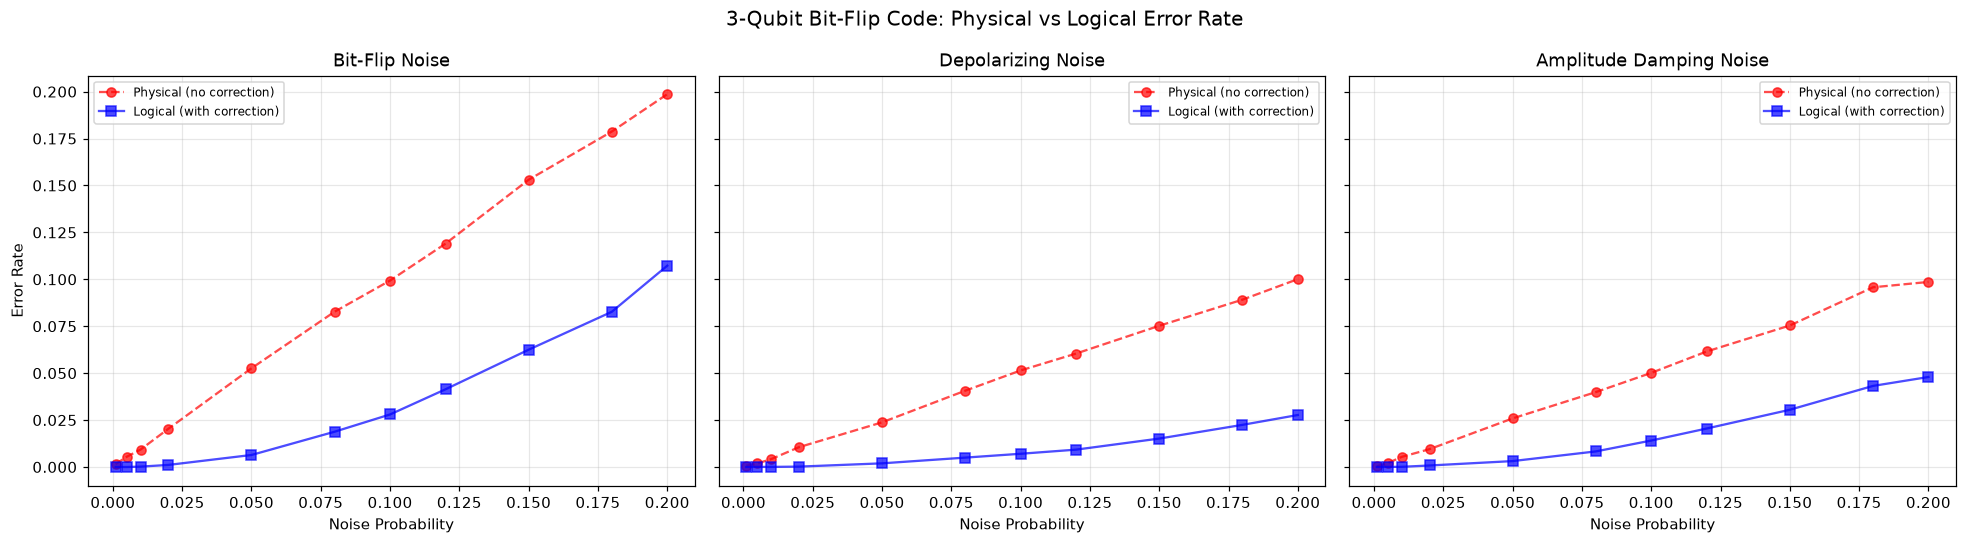

Where blue is BELOW red → the code is helping
Where they cross → pseudo-threshold (breakeven point)


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, noise_type in zip(axes, noise_makers):
    subset = results_df[results_df.noise_type == noise_type]
    
    # Average over test states for a cleaner plot
    avg = subset.groupby('noise_prob').agg({
        'physical_error_rate': 'mean',
        'logical_error_rate': 'mean'
    }).reset_index()
    
    # Plot physical error rate (baseline — no correction)
    ax.plot(avg.noise_prob, avg.physical_error_rate, 
            'r--o', label='Physical (no correction)', alpha=0.7)
    
    # Plot logical error rate (with correction)
    ax.plot(avg.noise_prob, avg.logical_error_rate, 
            'b-s', label='Logical (with correction)', alpha=0.7)
    
    # Mark where they cross (pseudo-threshold)
    ax.set_title(f'{noise_type} Noise')
    ax.set_xlabel('Noise Probability')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel('Error Rate')
fig.suptitle('3-Qubit Bit-Flip Code: Physical vs Logical Error Rate', fontsize=13)
fig.tight_layout()

import os
os.makedirs('outputs/Phase2_BitFlip_Code', exist_ok=True)
fig.savefig('outputs/Phase2_BitFlip_Code/bitflip_physical_vs_logical.png', dpi=150, bbox_inches='tight')
plt.show()

print('Where blue is BELOW red → the code is helping')
print('Where they cross → pseudo-threshold (breakeven point)')

---
## Step 7: Find the Pseudo-Threshold

The pseudo-threshold is the noise probability where logical error rate = physical error rate.
Below this point, the code helps. Above it, the code makes things worse.

We find it by looking for where the logical error rate crosses the physical error rate.

In [7]:
print('Pseudo-Threshold Estimates (Bit-Flip Code)')
print('=' * 55)

for noise_type in noise_makers:
    subset = results_df[results_df.noise_type == noise_type]
    avg = subset.groupby('noise_prob').agg({
        'physical_error_rate': 'mean',
        'logical_error_rate': 'mean'
    }).reset_index()
    
    # Find where logical crosses physical
    # (where logical goes from being less than physical to being more)
    threshold_found = False
    for i in range(1, len(avg)):
        phys_prev = avg.iloc[i-1]['physical_error_rate']
        phys_curr = avg.iloc[i]['physical_error_rate']
        log_prev = avg.iloc[i-1]['logical_error_rate']
        log_curr = avg.iloc[i]['logical_error_rate']
        
        # Check if logical crosses physical between these two points
        if log_prev <= phys_prev and log_curr >= phys_curr:
            # Linear interpolation to estimate the crossing point
            p_low = avg.iloc[i-1]['noise_prob']
            p_high = avg.iloc[i]['noise_prob']
            diff_prev = phys_prev - log_prev
            diff_curr = log_curr - phys_curr
            threshold = p_low + (p_high - p_low) * diff_prev / (diff_prev + diff_curr)
            print(f'{noise_type:20s} → Pseudo-threshold ≈ {threshold:.4f} ({threshold*100:.2f}%)')
            threshold_found = True
            break
    
    if not threshold_found:
        # Check if code always helps or never helps
        always_helps = all(avg.logical_error_rate <= avg.physical_error_rate)
        if always_helps:
            print(f'{noise_type:20s} → Code always helps in tested range (threshold > 20%)')
        else:
            print(f'{noise_type:20s} → Code never helps (threshold < 0.1%)')

Pseudo-Threshold Estimates (Bit-Flip Code)
Bit-Flip             → Code always helps in tested range (threshold > 20%)
Depolarizing         → Code always helps in tested range (threshold > 20%)
Amplitude Damping    → Code always helps in tested range (threshold > 20%)


---
## Step 8: Fidelity Analysis (Post-Correction)

Measure how close the corrected state is to the original ideal state.
We use density matrix simulation (same as Phase 1) but now on the ENCODED + CORRECTED circuit.

**Note:** For fidelity, we need a slightly different circuit — we save the density matrix
instead of measuring, so we can compute fidelity mathematically.

In [8]:
def build_bitflip_fidelity_circuit(initial_state='0'):
    """
    Build a simplified bit-flip circuit for fidelity measurement.
    Uses density matrix simulation — no classical measurement.
    
    Since we can't use c_if with density matrix simulation,
    we compute fidelity by running many shots and calculating
    the fraction of correct outcomes.
    """
    # We use the shot-based circuit and compute fidelity from statistics
    return build_bitflip_circuit(initial_state)


def measure_corrected_fidelity(initial_state, noise_type, noise_prob, num_shots=10000):
    """
    Estimate fidelity from measurement statistics.
    Fidelity ≈ fraction of correct outcomes.
    (For computational basis states this is exact.)
    """
    circuit = build_bitflip_circuit(initial_state)
    noise_model = noise_makers[noise_type](noise_prob)
    sim = AerSimulator(noise_model=noise_model)
    counts = sim.run(circuit, shots=num_shots).result().get_counts()
    
    correct_output = '0' if initial_state == '0' else '1'
    correct_count = 0
    for bitstring, count in counts.items():
        # The output bit is the first register in the bitstring
        # (output_bit was created after syndrome_bits, so it's listed leftmost)
        output = bitstring.split()[0]
        if output == correct_output:
            correct_count += count
    
    return correct_count / num_shots


# === RUN FIDELITY EXPERIMENTS ===
fidelity_results = []

for noise_type in noise_makers:
    for state in ['0', '1']:
        for p in noise_levels:
            fid = measure_corrected_fidelity(state, noise_type, p)
            fidelity_results.append({
                'noise_type': noise_type,
                'initial_state': f'|{state}⟩',
                'noise_prob': p,
                'fidelity_corrected': round(fid, 4)
            })

fidelity_df = pd.DataFrame(fidelity_results)
print(f'Fidelity experiments: {len(fidelity_df)}')
fidelity_df.head(10)

Fidelity experiments: 66


,noise_type,initial_state,noise_prob,fidelity_corrected
0,Bit-Flip,|0⟩,0.001,1.0000
1,Bit-Flip,|0⟩,0.005,1.0000
2,Bit-Flip,|0⟩,0.010,0.9997
3,Bit-Flip,|0⟩,0.020,0.9989
4,Bit-Flip,|0⟩,0.050,0.9921
5,Bit-Flip,|0⟩,0.080,0.9827
6,Bit-Flip,|0⟩,0.100,0.9720
7,Bit-Flip,|0⟩,0.120,0.9596
8,Bit-Flip,|0⟩,0.150,0.9419
9,Bit-Flip,|0⟩,0.180,0.9111


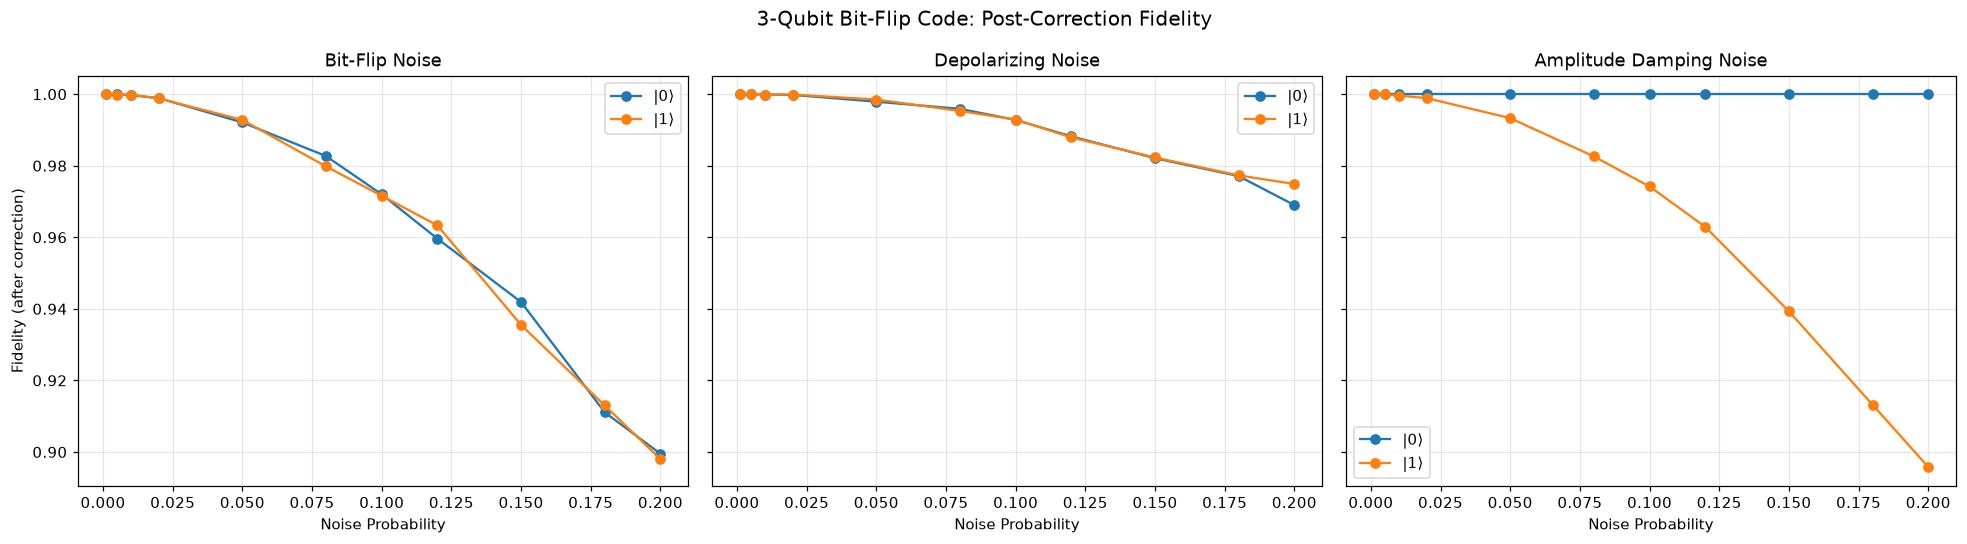

In [9]:
# Plot fidelity vs noise probability for each noise type
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, noise_type in zip(axes, noise_makers):
    subset = fidelity_df[fidelity_df.noise_type == noise_type]
    
    for state_name, group in subset.groupby('initial_state'):
        ax.plot(group.noise_prob, group.fidelity_corrected, marker='o', label=state_name)
    
    ax.set_title(f'{noise_type} Noise')
    ax.set_xlabel('Noise Probability')
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel('Fidelity (after correction)')
fig.suptitle('3-Qubit Bit-Flip Code: Post-Correction Fidelity', fontsize=13)
fig.tight_layout()

import os
os.makedirs('outputs/Phase2_BitFlip_Code', exist_ok=True)
fig.savefig('outputs/Phase2_BitFlip_Code/bitflip_fidelity_post_correction.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Step 9: Compare with Base Paper's Predicted Scaling

Thakur et al. (2025) predict: $P_L \propto P_p^{(d+1)/2}$

For our 3-qubit code, d = 3, so the exponent = 2. This means $P_L \propto P_p^2$.

Let's plot our measured logical error rate vs the predicted quadratic curve and see if they match.

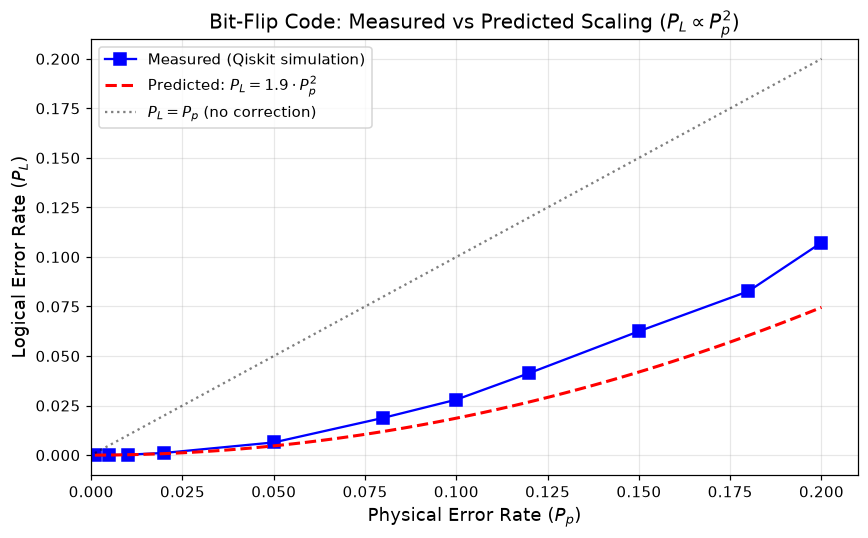

Fitted scaling constant A = 1.86
Predicted: P_L = 1.86 × P_p²
At P_p = 5%: predicted P_L = 0.00466
At P_p = 5%: measured  P_L = 0.00640


In [10]:
# Focus on Bit-Flip noise (where the code is designed to work best)
bf_data = results_df[results_df.noise_type == 'Bit-Flip'].groupby('noise_prob').agg({
    'logical_error_rate': 'mean'
}).reset_index()

# Generate the predicted curve: P_L = A * P_p^2
# We fit the constant A from our data (low noise regime)
low_noise = bf_data[bf_data.noise_prob <= 0.10]
if len(low_noise) > 0 and low_noise.logical_error_rate.sum() > 0:
    # Estimate A by fitting P_L = A * P_p^2 in low noise region
    A_fit = np.mean(low_noise.logical_error_rate / (low_noise.noise_prob ** 2))
else:
    A_fit = 3.0  # Theoretical value for 3-qubit code

p_range = np.linspace(0.001, 0.20, 100)
predicted_PL = A_fit * p_range ** 2

# Plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(bf_data.noise_prob, bf_data.logical_error_rate, 
        'bs-', label='Measured (Qiskit simulation)', markersize=8)
ax.plot(p_range, predicted_PL, 
        'r--', label=f'Predicted: $P_L = {A_fit:.1f} \cdot P_p^2$', linewidth=2)
ax.plot(p_range, p_range, 
        'k:', label='$P_L = P_p$ (no correction)', alpha=0.5)

ax.set_xlabel('Physical Error Rate ($P_p$)', fontsize=12)
ax.set_ylabel('Logical Error Rate ($P_L$)', fontsize=12)
ax.set_title('Bit-Flip Code: Measured vs Predicted Scaling ($P_L \propto P_p^2$)', fontsize=13)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
ax.set_xlim(0, 0.21)
fig.tight_layout()

import os
os.makedirs('outputs/Phase2_BitFlip_Code', exist_ok=True)
fig.savefig('outputs/Phase2_BitFlip_Code/bitflip_scaling_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Fitted scaling constant A = {A_fit:.2f}')
print(f'Predicted: P_L = {A_fit:.2f} × P_p²')
print(f'At P_p = 5%: predicted P_L = {A_fit * 0.05**2:.5f}')
print(f'At P_p = 5%: measured  P_L = {bf_data[bf_data.noise_prob==0.05].logical_error_rate.values[0]:.5f}')

---
## Step 10: Save All Results

In [11]:
import os
os.makedirs('outputs/Phase2_BitFlip_Code', exist_ok=True)
results_df.to_csv('outputs/Phase2_BitFlip_Code/bitflip_error_rates.csv', index=False)
fidelity_df.to_csv('outputs/Phase2_BitFlip_Code/bitflip_fidelity_results.csv', index=False)

print('Saved: outputs/Phase2_BitFlip_Code/bitflip_error_rates.csv')
print('Saved: outputs/Phase2_BitFlip_Code/bitflip_fidelity_results.csv')
print()
print('Bit-Flip Code notebook complete!')
print('Next: Phase-Flip Code notebook')

Saved: outputs/Phase2_BitFlip_Code/bitflip_error_rates.csv
Saved: outputs/Phase2_BitFlip_Code/bitflip_fidelity_results.csv

Bit-Flip Code notebook complete!
Next: Phase-Flip Code notebook
